# Actividad 3 – Colab–VS Code Bridge
**Curso:** TI2006B · **Alumna:** Jessica Lizeth Salazar Muñoz (A01572331)

## Pregunta
¿Existe relación entre las horas de estudio semanales y la calificación final en un grupo simulado de estudiantes?

## Procedencia de los datos
Los datos son **100 % sintéticos**: se generan dentro de este notebook con `numpy` y una semilla fija (`SEED = 42`). No se usan archivos locales, Google Drive ni datos personales o confidenciales.

## Resultado esperado
- Tabla resumen de los datos generados.
- Coeficiente de correlación de Pearson y una recta de regresión lineal simple.
- Una gráfica de dispersión con la recta ajustada.
- Una conclusión breve.

> Este notebook debe poder ejecutarse con **Runtime → Run all** desde una sesión nueva de Colab, sin depender de variables creadas antes.

## 1. Setup
Imprime la versión de Python e instala/importa solo lo necesario. `numpy`, `pandas` y `matplotlib` ya vienen en Colab; la celda los instala solo si faltan (por ejemplo, en un entorno local).

In [1]:
import sys, platform, importlib, subprocess

print("Python:", sys.version)
print("Plataforma:", platform.platform())

# Detectar en qué runtime se ejecuta
try:
    import google.colab  # noqa: F401
    RUNTIME = "Google Colab (hosted runtime)"
except ImportError:
    RUNTIME = "Local / otro kernel"
print("Runtime:", RUNTIME)

REQUIRED = ["numpy", "pandas", "matplotlib"]
for pkg in REQUIRED:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

for pkg in REQUIRED:
    print(f"{pkg}=={importlib.import_module(pkg).__version__}")

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Plataforma: Linux-6.6.159+-x86_64-with-glibc2.39
Runtime: Google Colab (hosted runtime)
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0


## 2. Datos sintéticos
Se simulan 50 estudiantes. La calificación depende de las horas de estudio más ruido aleatorio, y se limita al rango 0–100.

In [2]:
SEED = 42
rng = np.random.default_rng(SEED)

n = 50
horas = rng.uniform(1, 15, size=n).round(1)
ruido = rng.normal(0, 8, size=n)
calificacion = np.clip(55 + 3 * horas + ruido, 0, 100).round(1)

df = pd.DataFrame({"horas_estudio": horas, "calificacion": calificacion})
print(df.shape)
df.head()

(50, 2)


,horas_estudio,calificacion
0,11.8,95.8
1,7.1,76.8
2,13.0,96.3
3,10.8,92.5
4,2.3,50.2


## 3. Análisis

       horas_estudio  calificacion
count          50.00         50.00
mean            8.50         79.06
std             3.93         13.36
min             1.60         50.20
25%             5.45         68.75
50%             8.25         80.40
75%            11.88         89.78
max            14.70        100.00

Correlación de Pearson r = 0.893
Recta ajustada: calificacion = 53.26 + 3.04 * horas


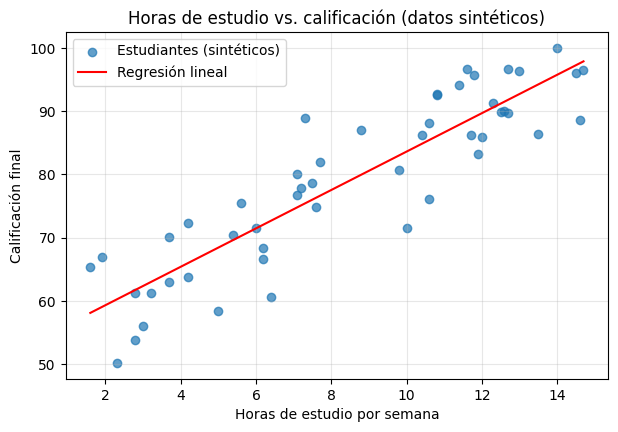

In [3]:
print(df.describe().round(2))

r = df["horas_estudio"].corr(df["calificacion"])
pendiente, intercepto = np.polyfit(df["horas_estudio"], df["calificacion"], 1)
print(f"\nCorrelación de Pearson r = {r:.3f}")
print(f"Recta ajustada: calificacion = {intercepto:.2f} + {pendiente:.2f} * horas")

x = np.linspace(df["horas_estudio"].min(), df["horas_estudio"].max(), 100)
plt.figure(figsize=(7, 4.5))
plt.scatter(df["horas_estudio"], df["calificacion"], alpha=0.7, label="Estudiantes (sintéticos)")
plt.plot(x, intercepto + pendiente * x, color="red", label="Regresión lineal")
plt.xlabel("Horas de estudio por semana")
plt.ylabel("Calificación final")
plt.title("Horas de estudio vs. calificación (datos sintéticos)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Conclusión

In [4]:
print(f"Ejecutado en: {RUNTIME}")
print(f"Con datos sintéticos (semilla {SEED}), la correlación es r = {r:.2f}: "
      f"por cada hora extra de estudio, la calificación sube en promedio {pendiente:.2f} puntos.")

Ejecutado en: Google Colab (hosted runtime)
Con datos sintéticos (semilla 42), la correlación es r = 0.89: por cada hora extra de estudio, la calificación sube en promedio 3.04 puntos.


**Interpretación:** en estos datos simulados hay una relación positiva fuerte entre horas de estudio y calificación. Como los datos fueron generados con esa relación, el resultado sirve para validar el flujo GitHub → Colab → GitHub, no para sacar conclusiones sobre estudiantes reales.

### Nota sobre notebook vs. runtime
Lo que queda guardado en GitHub es el **archivo** `.ipynb` (código, texto y las salidas de la última ejecución). El **runtime** (memoria, variables, paquetes instalados, archivos temporales de Colab) **no** se guarda ni se comparte: otra persona que abra este notebook debe volver a ejecutarlo desde cero.